# Selector design

Clipped allocation, tanh smoothing, and a neutral deadband share the stabilization scale $\tau_c=\beta/(1+\rho)$, while hysteresis suppresses repeated switching only at the larger threshold $h_{\mathrm{hys}}=\beta/(1-\rho)$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from dynafront.certificates import hysteresis_over_tau_c_ratio, hysteresis_threshold, tau_c
from dynafront.dynamics import simulate_hysteresis, simulate_scalar, simulate_tanh
from dynafront.selectors import clipped, deadband, sign_plus_at_zero

rho, beta = 0.5, 1.0
t = tau_c(rho, beta)
h_hys = hysteresis_threshold(rho, beta)
print("tau_c", t)
print("h_hys", h_hys)
print("ratio identity", hysteresis_over_tau_c_ratio(rho), (1 + rho) / (1 - rho))

tau_c 0.6666666666666666
h_hys 2.0
ratio identity 3.0 3.0


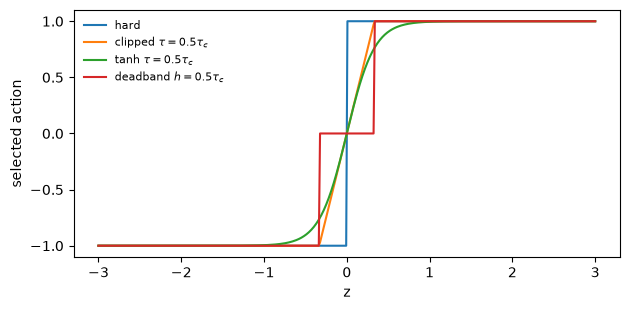

In [2]:
z = np.linspace(-3, 3, 400)
fig, ax = plt.subplots(figsize=(6.4, 3.2))
ax.plot(z, sign_plus_at_zero(z), label="hard")
ax.plot(z, clipped(z, 0.5 * t), label=r"clipped $\tau=0.5\tau_c$")
ax.plot(z, np.tanh(z / (0.5 * t)), label=r"tanh $\tau=0.5\tau_c$")
ax.plot(z, deadband(z, 0.5 * t), label=r"deadband $h=0.5\tau_c$")
ax.set_xlabel("z")
ax.set_ylabel("selected action")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

At the shared numerical value $\tau=\tau_c$ the clipped map is neutrally sloped through the origin. Slightly below, trajectories track the hard cycle; slightly above, they go to zero. Deadband selects $a=0$ inside $|z|\le h$ and therefore coexists a zero basin with a cycle basin when $h<\tau_c$. Hysteresis compares against $h_{\mathrm{hys}}$ and, on equality, keeps the previous action.

In [3]:
z0 = np.array([2.5, 0.2, -1.8])
zh, _ = simulate_scalar(z0, rho, 80, "hard")
zc, _ = simulate_scalar(z0, rho, 80, "continuous", tau=0.5 * t)
zd, _ = simulate_scalar(z0, rho, 80, "deadband", h=0.5 * t)
zt = simulate_tanh(z0, rho, 0.5 * t, 80)
a0 = np.ones(3)
zhy, _ = simulate_hysteresis(z0, a0, rho, 0.5 * h_hys, 80)
print("terminals hard/clip/dead/tanh/hys")
print(zh[-1])
print(zc[-1])
print(zd[-1])
print(zt[-1])
print(zhy[-1])

terminals hard/clip/dead/tanh/hys
[-0.66666667  0.66666667 -0.66666667]
[-0.66666667  0.66666667 -0.66666667]
[4.13590306e-25 1.65436123e-25 1.65436123e-25]
[-0.63833602  0.63833602 -0.63833602]
[ 0.4  1.2 -1.2]


Near versus at threshold: run clipped at $0.99\tau_c$ and at $\tau_c$ from the same initial condition.

In [4]:
z_near, _ = simulate_scalar(np.array([2.0]), rho, 400, "continuous", tau=0.99 * t)
z_at, _ = simulate_scalar(np.array([2.0]), rho, 400, "continuous", tau=t)
print("near threshold |z_T|", abs(z_near[-1, 0]))
print("at threshold |z_T|", abs(z_at[-1, 0]))

near threshold |z_T| 0.0
at threshold |z_T| 0.0


Full selector families:

```bash
python -m dynafront.cli reproduce --mode paper
```

Families: `synthetic_a`, `tanh`, `hysteresis`.